# 以齒槽骨高度定義臨床冠根比（CRR）

**本研究的定義（臨床版）**：參考線不是解剖上的 CEJ，而是**牙齒左右兩側的齒槽骨頂（alveolar crest）連線**。

- `A`：牙冠頂端、`B`：根尖（沿牙齒長軸）
- `O`：齒槽骨頂連線與長軸的交點
- 臨床牙冠 = `|AO|`（骨上方）、臨床牙根 = `|OB|`（骨內）、**CRR = |AO| / |OB|**

**方法**（實作在 `src/segmentation/alveolar.py`，有單元測試）

1. 調整明暗對比：以有效像素的 1–99 百分位正規化，再 CLAHE（原圖解析度，不是 256×256 的 ROI）
2. 牙齒長軸：目標牙 mask 的 PCA，方向統一為「牙冠 → 牙根」（較窄端為牙根），`A`、`B` 取投影 1%／99% 百分位
3. 轉到軸座標系（長軸垂直、牙冠朝上）
4. 每側在牙齒輪廓外側取一條**側向取樣帶**，得到沿軸的「骨亮度剖面」；**鄰牙、金屬、補邊與牙齒本身不納入取樣**
5. 齒槽骨頂 = 剖面中「上暗下亮」的明顯階梯，取**最靠牙冠端**且強度不低於最強者 60% 的那一個
6. 兩側骨頂連線與長軸交點即 `O`；單側失敗、連線近乎平行長軸、`O` 落在牙外、CRR 不合理都會回報 warning

**限制**：沒有醫師真值前，結果只是候選位置，不是臨床診斷；參數為初始值。**調參只看 val（或 train），test 保持凍結。**
標註工具 `research/data/annotate_cej.py` 點的兩點，在新定義下請解讀為「左右齒槽骨頂」，標註後可在第 6 節量化誤差。

In [24]:
import csv, json, sys
from pathlib import Path
from dataclasses import replace

ROOT = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "data/derived").is_dir())
sys.path.insert(0, str(ROOT))   # 讓 `src` 可被 import

import cv2
import matplotlib.pyplot as plt
import numpy as np

from src.segmentation.alveolar import (AlveolarConfig, load_crop, locate_alveolar_crest,
                                       reference_from_points, compare_with_reference)

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

DERIVED = sorted((ROOT / "data/derived").glob("roi_*"))[-1]          # 最新的 ROI 資料集
SEG_ROOT = ROOT / "data/seg_dataset"
SPLIT = "val"            # 調參／目視只用 val；test 保持凍結，最後一次性評估
CFG = AlveolarConfig()   # 所有可調參數集中於此
rows = [r for r in json.loads((DERIVED / "roi_index.json").read_text()) if r["subset"] == SPLIT]
print(DERIVED.name, SPLIT, len(rows), "ROIs")
CFG

roi_2a0c9441396f val 48 ROIs


AlveolarConfig(p_low=1.0, p_high=99.0, clahe_clip=2.0, clahe_grid=8, margin_frac=0.1, end_percentile=1.0, end_segment_frac=0.25, ambiguity=0.85, band_gap_frac=0.02, band_width_frac=0.12, min_band_valid_frac=0.5, smooth_sigma_frac=0.01, window_fracs=(0.03, 0.05, 0.08), t_range=(0.2, 0.95), coronal_frac=0.6, min_step=0.1, min_line_axis_angle_deg=25.0, plausible_crr=(0.1, 3.0), min_root_frac=0.05)

## 1. 單顆牙齒的完整除錯圖

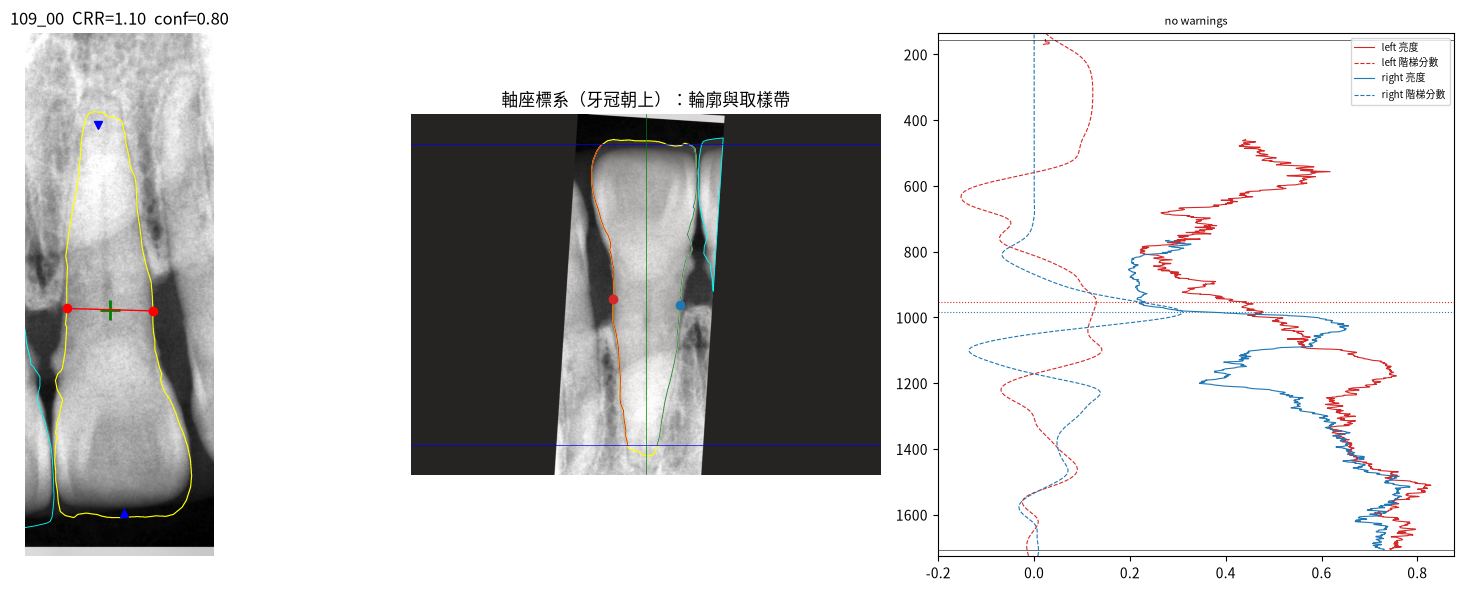

In [25]:
def run(row, cfg=CFG):
    c = load_crop(row, SEG_ROOT)
    trunc = bool(row["target_truncated_by_roi"] or row["truncated_at_source"])
    return c, locate_alveolar_crest(c["gray"], c["mask"], c["valid"], c["others"], cfg, truncated=trunc)


def debug_figure(row, cfg=CFG, gt_points=None):
    c, res = run(row, cfg)
    fig, ax = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    a = ax[0]
    a.imshow(res.get("contrast", c["gray"]), cmap="gray")
    a.contour(c["mask"], [0.5], colors="yellow", linewidths=0.8)
    a.contour(c["others"], [0.5], colors="cyan", linewidths=0.6)
    for p in res.get("crest_crop", {}).values():
        a.plot(*p, "ro", ms=6)
    if "O_crop" in res:
        a.plot(*res["O_crop"], "g+", ms=14, mew=2)
        a.plot(*res["A_crop"], "b^"); a.plot(*res["B_crop"], "bv")
        if len(res["crest_crop"]) == 2:
            (x0, y0), (x1, y1) = res["crest_crop"]["left"], res["crest_crop"]["right"]
            a.plot([x0, x1], [y0, y1], "r-", lw=1)
    if gt_points:
        a.plot(*np.array(gt_points).T, "m*", ms=10)
    a.set_title(f"{row['roi_id']}  CRR={res.get('crr', float('nan')):.2f}  conf={res.get('confidence', 0):.2f}")
    a.axis("off")
    if "warped" in res:
        b = ax[1]
        w = res["warped"]
        b.imshow(w["image"], cmap="gray")
        b.contour(w["mask"], [0.5], colors="yellow", linewidths=0.8)
        b.contour(w["others"], [0.5], colors="cyan", linewidths=0.6)
        b.imshow(np.ma.masked_where(w["usable"], np.ones_like(w["image"])), cmap="Reds", alpha=0.15)
        for s, col in (("left", "tab:red"), ("right", "tab:blue")):
            e = res["per_side"][s]["edge"]
            b.plot(e, np.arange(len(e)), color=col, lw=0.6)
            if s in res["crest_frame"]:
                b.plot(*res["crest_frame"][s], "o", color=col, ms=6)
        b.axhline(res["frame"]["yA"], color="b", lw=0.5); b.axhline(res["frame"]["yB"], color="b", lw=0.5)
        b.axvline(res["frame"]["xc"], color="g", lw=0.5)
        b.set_title("軸座標系（牙冠朝上）：輪廓與取樣帶"); b.axis("off")
        d = ax[2]
        y = np.arange(len(res["per_side"]["left"]["profile"]))
        for s, col in (("left", "tab:red"), ("right", "tab:blue")):
            ps = res["per_side"][s]
            d.plot(ps["profile"], y, color=col, lw=0.8, label=f"{s} 亮度")
            d.plot(ps["score"], y, color=col, lw=0.8, ls="--", label=f"{s} 階梯分數")
            if ps["y"] is not None:
                d.axhline(ps["y"], color=col, lw=0.8, ls=":")
        d.axhline(res["frame"]["yA"], color="k", lw=0.4); d.axhline(res["frame"]["yB"], color="k", lw=0.4)
        d.set_ylim(res["frame"]["yB"] + 20, res["frame"]["yA"] - 20)
        d.legend(fontsize=7); d.set_title(";".join(res["warnings"]) or "no warnings", fontsize=8)
    plt.tight_layout(); plt.show()
    return res


_ = debug_figure(rows[0])

## 2. 一批牙齒的總覽（val）

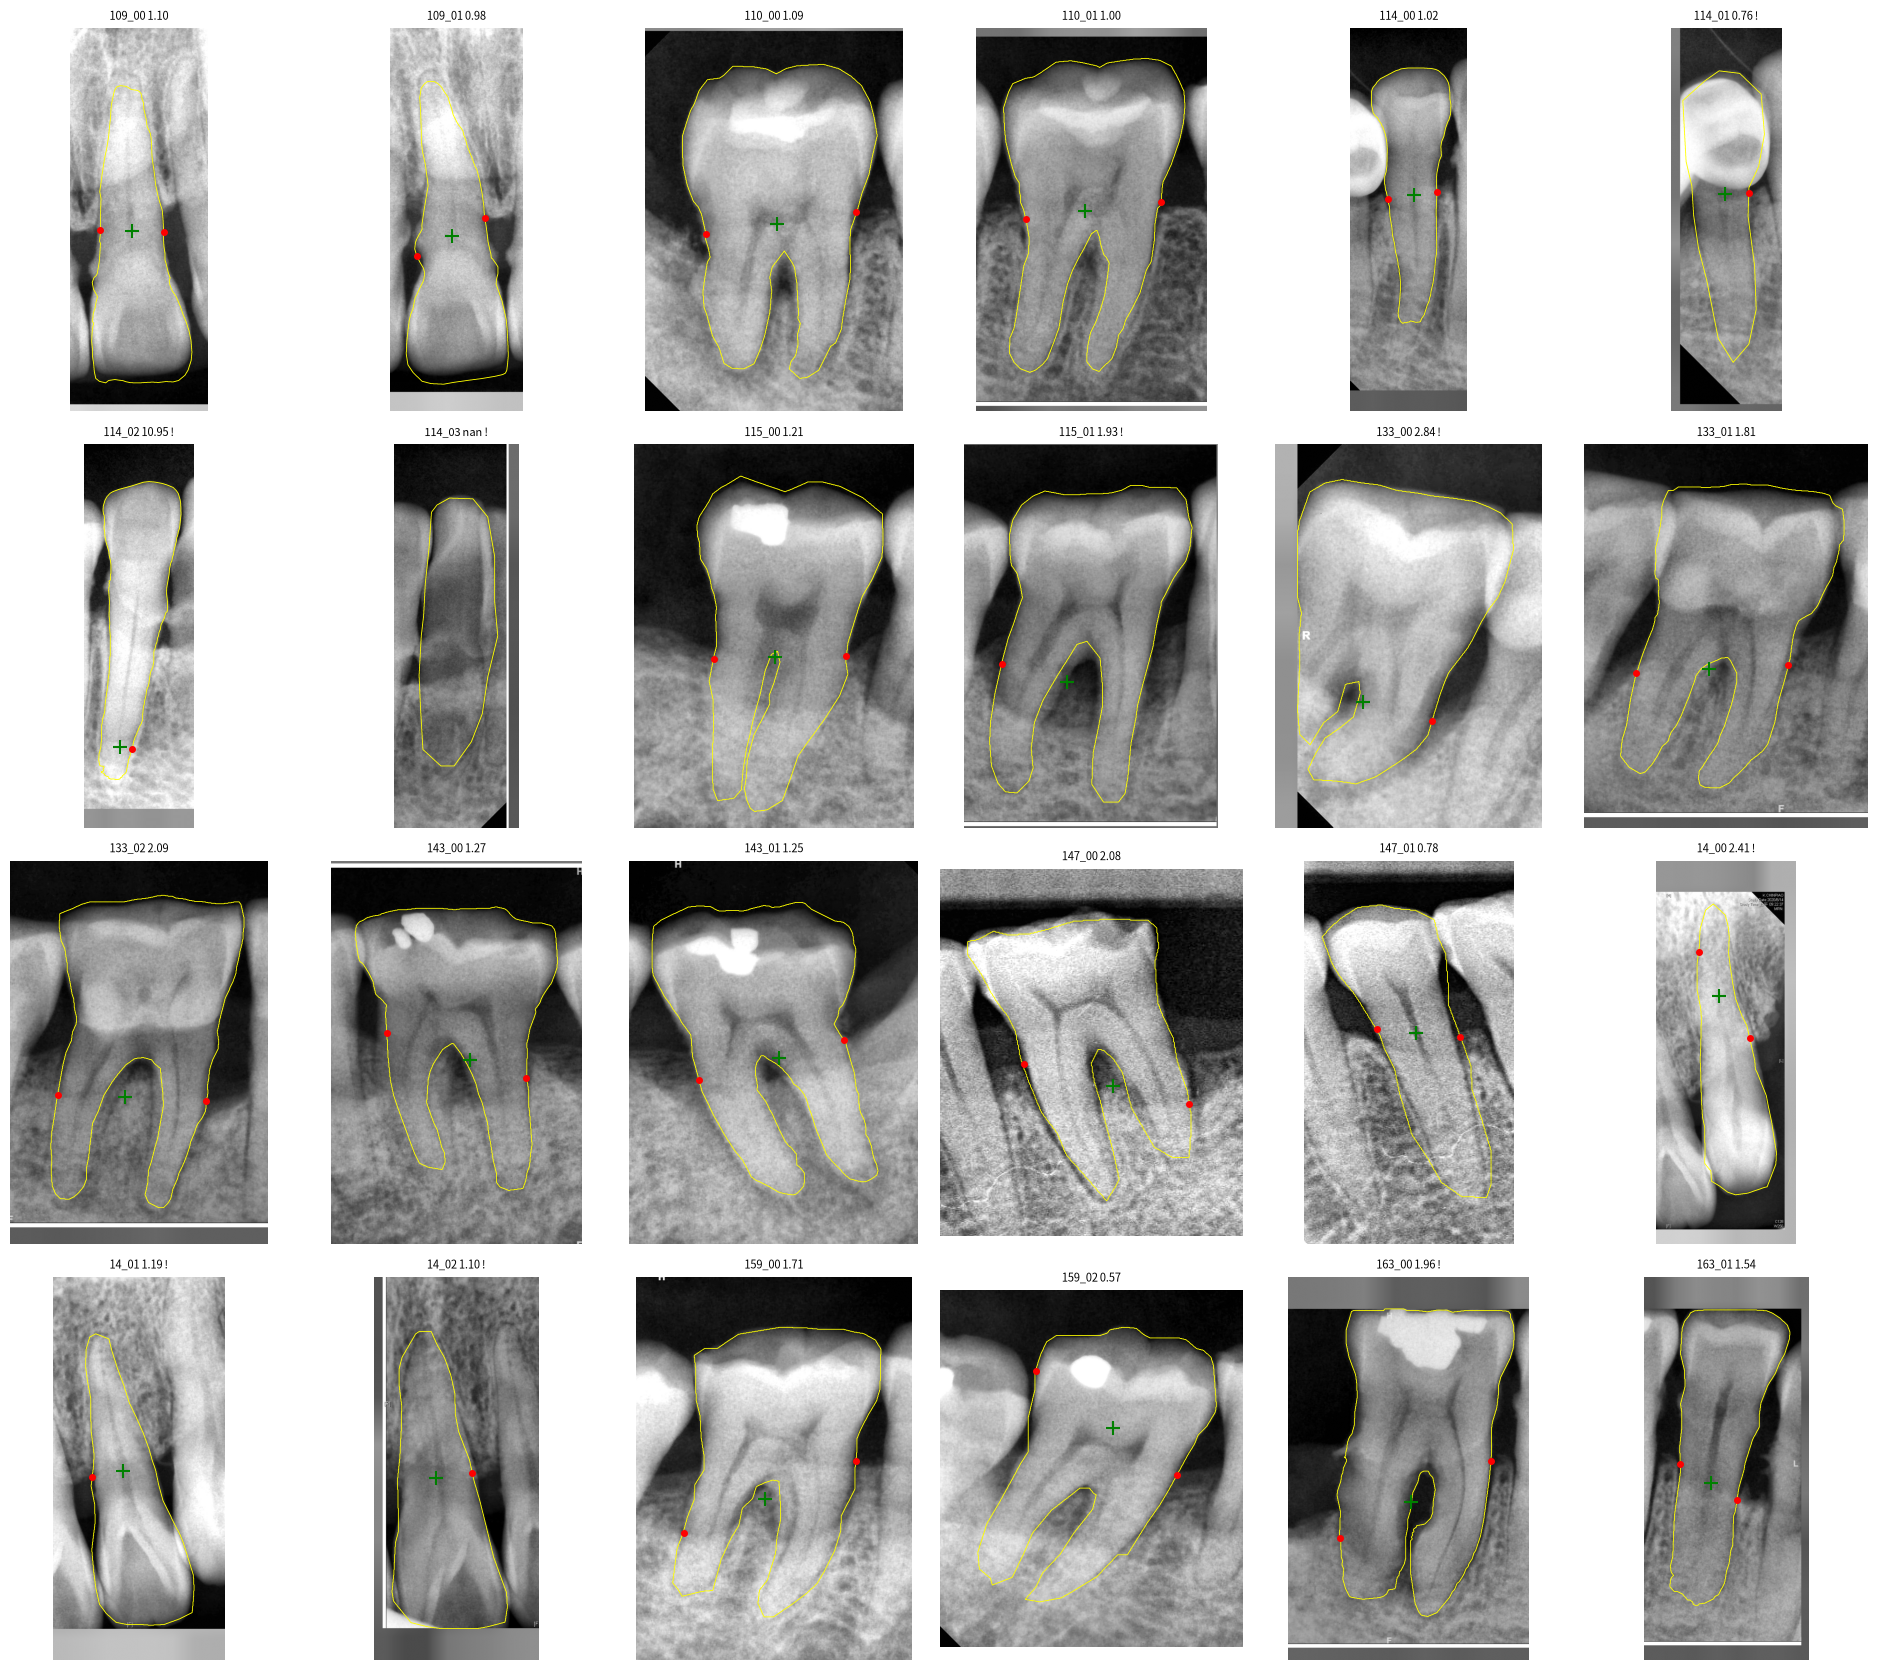

In [26]:
def overview(sel, cfg=CFG, ncols=6):
    n = len(sel); nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 4.2 * nrows))
    for a in np.atleast_1d(axs).ravel():
        a.axis("off")
    for a, r in zip(np.atleast_1d(axs).ravel(), sel):
        c, res = run(r, cfg)
        a.imshow(res.get("contrast", c["gray"]), cmap="gray")
        a.contour(c["mask"], [0.5], colors="yellow", linewidths=0.6)
        for p in res.get("crest_crop", {}).values():
            a.plot(*p, "ro", ms=4)
        if "O_crop" in res:
            a.plot(*res["O_crop"], "g+", ms=10, mew=1.5)
        a.set_title(f"{r['roi_id']} {res.get('crr', float('nan')):.2f}" + (" !" if res["warnings"] else ""), fontsize=8)
    plt.tight_layout(); plt.show()


overview(rows[:24])

## 3. 參數試驗（只在 val 上）

調整 `AlveolarConfig` 的欄位後重畫，例如：側向取樣帶寬 `band_width_frac`、CLAHE 強度 `clahe_clip`、
「最靠牙冠端」的門檻 `coronal_frac`、最小階梯 `min_step`、搜尋範圍 `t_range`。每次調整請記下理由。

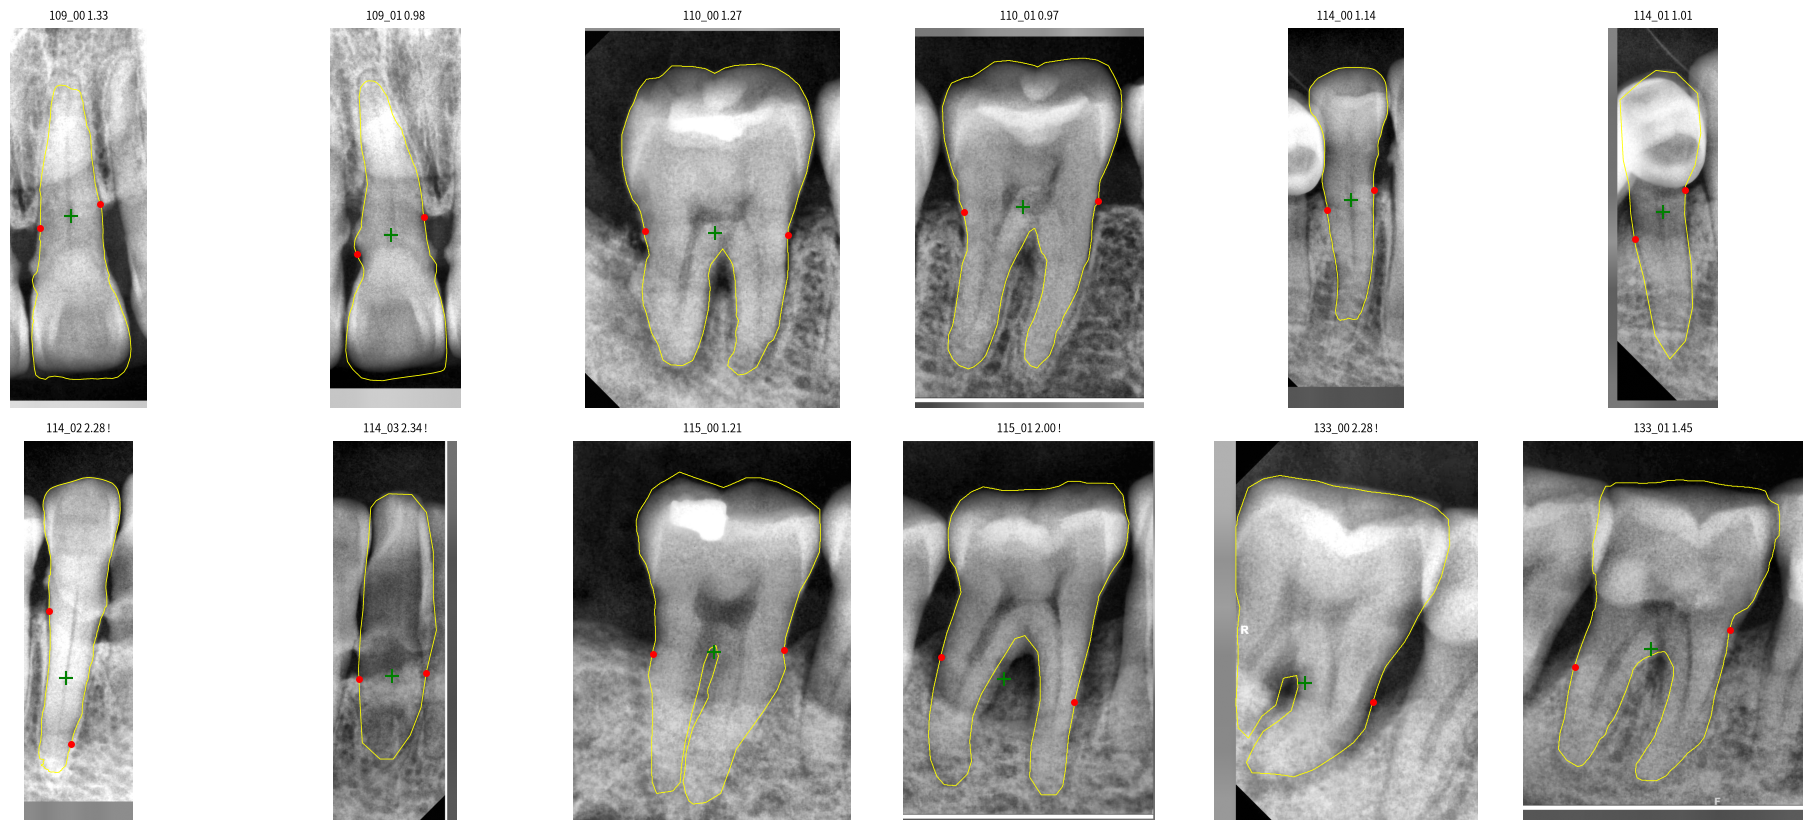

In [27]:
CFG2 = replace(CFG, clahe_clip=3.0, band_width_frac=0.08, coronal_frac=0.5)
overview(rows[:12], CFG2, ncols=6)

## 4. 整批執行並統計（val）

status: Counter({'ok': 45, 'failed': 3})
warnings: Counter({'single_side_horizontal_reference': 14, 'no_crest_left': 11, 'no_crest_right': 9, 'tooth_truncated_apex_or_crown_unreliable': 3, 'crr_implausible': 2, 'orientation_unclear': 2, 'crest_line_nearly_parallel_to_axis': 1})
CRR n=45 median=1.27 p5=0.76 p95=2.80


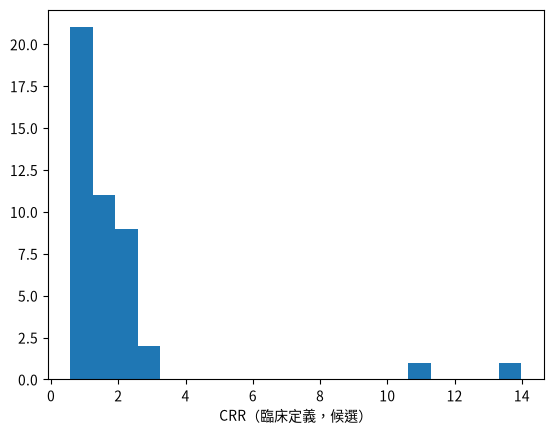

In [28]:
def run_all(sel, cfg=CFG):
    out = []
    for r in sel:
        _, res = run(r, cfg)
        out.append({"roi_id": r["roi_id"], "status": res["status"], "crr": res.get("crr"),
                    "confidence": res.get("confidence"), "crown_px": res.get("crown_px"), "root_px": res.get("root_px"),
                    "axis_len_px": res["axis"]["length"] if "axis" in res else None,
                    "n_sides": len(res.get("crest_crop", {})), "warnings": ";".join(res["warnings"])})
    return out


results = run_all(rows)
from collections import Counter
print("status:", Counter(r["status"] for r in results))
print("warnings:", Counter(w for r in results for w in r["warnings"].split(";") if w))
crr = np.array([r["crr"] for r in results if r["crr"] is not None])
print(f"CRR n={len(crr)} median={np.median(crr):.2f} p5={np.percentile(crr, 5):.2f} p95={np.percentile(crr, 95):.2f}")
plt.hist(crr, bins=20); plt.xlabel("CRR（臨床定義，候選）"); plt.show()

## 5. 存檔

結果寫到 `reports/segmentation/alveolar/`。這是**演算法候選值**，不是真值。

In [29]:
OUT = ROOT / "reports/segmentation/alveolar"
OUT.mkdir(parents=True, exist_ok=True)
path = OUT / f"{DERIVED.name}_{SPLIT}_candidates.csv"
with open(path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(results[0]))
    w.writeheader(); w.writerows(results)
(OUT / f"{DERIVED.name}_{SPLIT}_config.json").write_text(json.dumps(CFG.__dict__, default=list, indent=1))
print("saved", path)

saved /home/cliffyang/Program/Medical-CV/IOT-Program/CRR_Ratio/reports/segmentation/alveolar/roi_2a0c9441396f_val_candidates.csv


## 6. 與標註真值比較

用 `research/data/annotate_cej.py` 標註**左右齒槽骨頂**後，這裡量化演算法誤差（以軸長百分比表示，沒有 mm 標定）：
`axis_level_error_frac`（O 沿軸高度誤差）、兩側骨頂的沿軸／點誤差、CRR 絕對誤差。

In [30]:
ANN = ROOT / f"data/cej_annotations/cej_roi_2a0c9441396f.json"
if not ANN.exists():
    print("尚無標註檔：", ANN)
else:
    ann = json.loads(ANN.read_text())["teeth"]
    by_id = {r["roi_id"]: r for r in rows}
    errs = []
    for rid, rec in ann.items():
        if rec["status"] != "annotated" or rid not in by_id:
            continue
        row = by_id[rid]
        c, res = run(row)
        x0, y0 = row["expanded_xyxy"][:2]
        pts_crop = [[x - x0, y - y0] for x, y in rec["points_original"]]
        ref = reference_from_points(res, pts_crop)
        if ref is None:
            continue
        e = compare_with_reference(res, ref)
        errs.append({"roi_id": rid, "gt_crr": ref["crr"], "pred_crr": res.get("crr"), **e})
    print(len(errs), "annotated teeth compared")
    for k in ("axis_level_error_frac", "left_axial_error_frac", "right_axial_error_frac", "crr_abs_error"):
        v = np.array([e[k] for e in errs if e.get(k) is not None])
        if len(v):
            print(f"{k}: n={len(v)} median={np.median(v):.3f} mean={v.mean():.3f} p90={np.percentile(v, 90):.3f}")

0 annotated teeth compared


標註涵蓋的子集： {'test': 46}
注意：含 test 子集。請只用「已凍結」的 CFG 評估一次；若依此結果調參，test 就不再是獨立評估集。
46 annotated teeth compared
axis_level_error_frac: n=36 median=0.029 mean=0.068 p90=0.173
left_axial_error_frac: n=31 median=0.025 mean=0.066 p90=0.161
right_axial_error_frac: n=31 median=0.032 mean=0.052 p90=0.149
crr_abs_error: n=36 median=0.189 mean=0.489 p90=1.519
CRR 相關係數 r=0.61  平均差(預測-標註)=+0.09


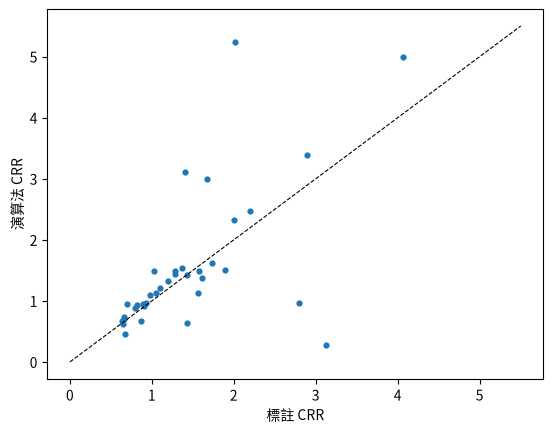

In [31]:
ANN = ROOT / f"data/cej_annotations/cej_{DERIVED.name}.json"
if not ANN.exists():
    print("尚無標註檔：", ANN)
else:
    ann = json.loads(ANN.read_text())["teeth"]
    all_rows = {r["roi_id"]: r for r in json.loads((DERIVED / "roi_index.json").read_text())}
    used = {rid: rec for rid, rec in ann.items() if rec["status"] == "annotated" and rid in all_rows}
    subsets = Counter(all_rows[rid]["subset"] for rid in used)
    print("標註涵蓋的子集：", dict(subsets))
    if subsets.get("test"):
        print("注意：含 test 子集。請只用「已凍結」的 CFG 評估一次；若依此結果調參，test 就不再是獨立評估集。")
    errs = []
    for rid, rec in used.items():
        row = all_rows[rid]
        c, res = run(row)
        x0, y0 = row["expanded_xyxy"][:2]
        pts_crop = [[x - x0, y - y0] for x, y in rec["points_original"]]
        ref = reference_from_points(res, pts_crop)
        if ref is None:
            continue
        e = compare_with_reference(res, ref)
        errs.append({"roi_id": rid, "gt_crr": ref["crr"], "pred_crr": res.get("crr"), "warnings": ";".join(res["warnings"]), **e})
    print(len(errs), "annotated teeth compared")
    for k in ("axis_level_error_frac", "left_axial_error_frac", "right_axial_error_frac", "crr_abs_error", "line_cosine", "line_angle_deg"):
        v = np.array([e[k] for e in errs if e.get(k) is not None])
        if len(v):
            print(f"{k}: n={len(v)} median={np.median(v):.3f} mean={v.mean():.3f} p90={np.percentile(v, 90):.3f}")
    g = np.array([e["gt_crr"] for e in errs if e["pred_crr"] is not None])
    p = np.array([e["pred_crr"] for e in errs if e["pred_crr"] is not None])
    if len(g) > 2:
        print(f"CRR 相關係數 r={np.corrcoef(g, p)[0, 1]:.2f}  平均差(預測-標註)={np.mean(p - g):+.2f}")
        plt.scatter(g, p, s=12); lim = [0, max(g.max(), p.max()) * 1.05]
        plt.plot(lim, lim, "k--", lw=0.8); plt.xlabel("標註 CRR"); plt.ylabel("演算法 CRR"); plt.show()
    # 骨頂連線方向的 cosine similarity（預測連線 vs 標註連線；兩者都由左指向右，值越接近 1 越相似）
    cs = np.array([e["line_cosine"] for e in errs if e.get("line_cosine") is not None])
    if len(cs):
        print(f"cosine similarity: n={len(cs)} median={np.median(cs):.4f} min={cs.min():.4f}  >=0.99: {np.mean(cs >= 0.99):.0%}  >=0.95: {np.mean(cs >= 0.95):.0%}")